# Practical Lab — Local AI with Ollama
**Running and Developing Local AI Applications** · PHD Student 

**Prerequisites:** Python 3.10+, basic Python, basic understanding of APIs, 8–16 GB RAM (NVIDIA GPU optional).

**Technologies:** Ollama · Python · REST API · `requests` · (optional) Open WebUI · a local LLM (Qwen, Gemma, Llama…)

> Ollama exposes a local HTTP service on `localhost:11434`, so the same model can be used from the terminal, Python, or any other software.

### How to use this notebook
- Run cells top to bottom. Cells starting with `!` run shell commands.
- Change `MODEL` / `MODEL2` below if the model names differ on your installation.
- Fill in the **✍️ Your answer** cells — they feed your final report.

## Part 1 — Understanding Local AI

**Cloud AI**
```
Python App → Internet → Cloud API → LLM
```
**Local AI**
```
Python App → localhost:11434 → Ollama → Local LLM → GPU / CPU
```
Advantages to investigate: **privacy**, **offline operation**, **no per-token cost**.
Trade-off: local models may be **less capable or slower** than frontier cloud models, depending on hardware and model size.

## Part 2 — Installing Ollama
### Exercise 1 — Verify the environment

In [1]:
import sys, platform
print("Python  :", sys.version)
print("System  :", platform.system(), platform.release())
assert sys.version_info >= (3, 10), "Python 3.10+ required"

Python  : 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
System  : Linux 7.0.0-34-generic


In [2]:
!pip --version

pip 24.0 from /home/ayaline/LocalAI_TP/venv/lib/python3.12/site-packages/pip (python 3.12)


### Exercise 2 — Install Ollama
Download the installer for your OS from <https://ollama.com/download> (Linux: `curl -fsSL https://ollama.com/install.sh | sh`). Then verify:

In [3]:
!ollama --version

]11;?\ollama version is 0.40.11


Make sure the Ollama service is running (the desktop app starts it automatically; otherwise run `ollama serve` in a separate terminal).

In [2]:
import requests

OLLAMA = "http://localhost:11434"

try:
    r = requests.get(OLLAMA, timeout=3)
    print("✅ Ollama server reachable:", r.text)
except requests.exceptions.ConnectionError:
    print("❌ Ollama is not running. Start it with `ollama serve` in a terminal.")

✅ Ollama server reachable: Ollama is running


## Part 3 — Your First Local LLM
### Exercise 3 — Download a model
If the exact name differs on your installation, pick a small instruct/chat model suited to your hardware.

In [3]:
# Models used throughout the lab — edit if needed
MODEL  = "qwen3.5:4b"   # Model 1
MODEL2 = "gemma3:4b"    # Model 2 (used in the comparison parts)

In [6]:
!ollama pull {MODEL}

]11;?\pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest 
pulling e56a899b1540:   0% ▕                  ▏ 492 KB/675 MB                  pulling manifest 
pulling e56a899b1540:   0% ▕             

In [89]:
!ollama list

]11;?\NAME          ID              SIZE      MODIFIED     
gemma3:4b     68ceab7e468a    3.4 GB    7 hours ago     
qwen3.5:4b    d8b0f5e9760c    3.3 GB    21 hours ago    


### Exercise 4 — Run the model
In the terminal you would use `ollama run qwen3.5`. Here we do the same thing through the API with a helper function.

In [4]:
import time, json

def generate(prompt, model=None, system=None, fmt=None, images=None, options=None, think=None):
    """Call Ollama /api/generate (non-streaming) and return the full JSON dict
    plus the measured wall-clock time under the key 'wall_s'."""
    payload = {"model": model or MODEL, "prompt": prompt, "stream": False}
    if system:  payload["system"] = system
    if fmt:     payload["format"] = fmt          # "json" or a JSON schema
    if images:  payload["images"] = images       # list of base64 strings
    if options: payload["options"] = options
    if think is not None: payload["think"] = think  # False disables 'thinking' on reasoning models
    t0 = time.perf_counter()
    r = requests.post(f"{OLLAMA}/api/generate", json=payload, timeout=600)
    r.raise_for_status()
    out = r.json()
    out["wall_s"] = time.perf_counter() - t0
    return out

def ask(prompt, **kw):
    """Shortcut: return only the text, and print timing."""
    out = generate(prompt, **kw)
    print(f"[{out['wall_s']:.1f}s]")
    return out["response"]

In [9]:
for p in [
    "Explain what artificial intelligence is in five sentences.",
    "Explain artificial intelligence to a 10-year-old child.",
    "Explain artificial intelligence to a computer science professor.",
]:
    print("="*80, "\nPROMPT:", p, "\n")
    print(ask(p))

PROMPT: Explain what artificial intelligence is in five sentences. 

[117.9s]
Artificial intelligence refers to the simulation of human intelligence in machines capable of performing tasks that typically require human cognition. These systems utilize complex algorithms and large datasets to learn from data rather than simply executing pre-programmed commands. A key aspect of modern AI involves machine learning, which enables computers to improve their accuracy and adapt through experience. Applications of this technology are widespread, including virtual assistants, predictive analytics, and autonomous robotics. Ultimately, the goal is to create tools that can assist humans by solving complex problems efficiently.
PROMPT: Explain artificial intelligence to a 10-year-old child. 

[175.2s]
Imagine you have a super-smart friend who loves to play games and look at pictures. That friend doesn’t need to eat or sleep! That’s basically what AI is.

**AI stands for Artificial Intelligence.** Yo

### Questions
1. Did the model produce different answers? Why?
2. Is the model communicating with a cloud API?
3. Where is inference being performed?
4. What happens if the Internet connection is disabled?

> 💡 Try it: disable Wi-Fi / unplug Ethernet and re-run the cell above.

**✍️ Your answer:**

1. Yes, the answers vary between runs because the model samples the next token randomly among likely candidates (controlled by 'temperature'). With temperature 0 and a fixed seed, outputs become nearly deterministic.
2. No. Requests are sent to 'localhost:11434', which is the Ollama server running on my own machine.
3. Inference runs locally on my CPU (no GPU detected); the model weights are loaded into RAM.
4. I disabled Wi-Fi and re-ran the cell: it still worked. Internet is only needed to download models (`ollama pull`), not to run them.

## Part 4 — Experiment with Prompts
### Exercise 5 — Prompt engineering

In [5]:
prompt_a = """You are a university professor.

Explain the concept of a Directed Acyclic Graph (DAG).

Your answer must contain:
1. Definition
2. Example
3. Adjacency matrix
4. Real-world application
5. One Python example"""

print(ask(prompt_a))

[327.4s]
Good morning, class. Please take a seat. Today, we are diving into a foundational structure of discrete mathematics and computer science: the **Directed Acyclic Graph**, or DAG. While graph theory is vast, understanding DAGs is crucial for understanding everything from compilation pipelines to project management systems.

### 1. Definition

A Directed Acyclic Graph is a fundamental data structure defined by two key properties:
*   **Directed:** It consists of **vertices** (nodes) connected by **directed edges**. Unlike an undirected graph, the connection has a specific direction (e.g., from $u$ to $v$, not necessarily from $v$ to $u$). This is often represented as $u \to v$.
*   **Acyclic:** There are no cycles in the graph. A cycle would occur if you could start at any vertex, traverse edges, and eventually return to the same starting vertex. If a directed path exists from vertex $A$ back to vertex $A$, it is not a DAG.

### 2. Example

Imagine a classroom scheduling problem.

In [6]:
prompt_b = """You are a university professor.

Explain DAGs to a first-year computer science student.

Use simple language and one concrete example."""

print(ask(prompt_b))

[190.6s]
Hello there! It is great to see a new first-year student here. Take a deep breath—you will find computer science concepts a bit like learning how your brain works; things build upon one another.

Today, we are going to talk about **DAGs**. That stands for **Directed Acyclic Graph**. This sounds very fancy and complicated, but if you break it down, it’s just describing how certain things must happen in a specific order without getting stuck in a loop.

Here is the simple explanation:

1.  **Graph:** Imagine a map of dots connected by lines.
2.  **Directed:** The lines are one-way arrows (like traffic).
3.  **Acyclic:** There are no loops or circles. If you follow an arrow, you can never get back to where you started.

### The Concrete Example: A Simple App Build

Imagine you and your team want to build a simple video game for school. You have three main tasks. Let's make them **Nodes** (dots).

*   **Node A:** Writing the Code
*   **Node B:** Testing the Bug Fixes
*   **Node C:

### Questions
Compare the two answers. Explain the role of: **role · context · constraints · output format · specificity**.

**✍️ Your answer:**

Prompt A (327 s) produced a long, technical lecture that followed the 5 requested sections in order: definition, course-prerequisite example, a correct adjacency matrix (A→B→C), a software-dependency application, and Python code. However, the first Python snippet was broken (many 'pass' statements, unfinished loops, an undefined variable 'remaining'); the model then added a second, correct version using 'networkx'. Prompt B (190 s) produced a shorter, friendly explanation with an analogy and one concrete example (Write code → Test → Publish), with no imposed structure.

- **Role**: "university professor" is in both prompts and gives a teaching tone ("Good morning, class" in A, "Hello there!" in B).
- **Context**: only B specifies the audience (first-year student). The model adapted with simple vocabulary, analogies (one-way traffic, "never go back into your past") and almost no jargon, while A used formal notation ($u \to v$, $N \times N$).
- **Constraints**: B's "simple language and one concrete example" was respected: a single 3-node example. A's five mandatory elements forced the model to cover topics it handles poorly (the code).
- **Output format**: A's numbered list was reproduced exactly as section headings (### 1. Definition … ### 5. Python example). B, with no format given, chose its own free structure.
- **Specificity**: a more specific prompt gives a more complete and predictable structure, but it does not guarantee correctness: A asked for more, and the small 4B model made more mistakes (broken code, a confusing sentence in the example). Both outputs also contain LaTeX, which does not render in a plain 'print', an output-format detail neither prompt specified.

Conclusion: role and context control tone and level, constraints and format control structure, and specificity controls completeness, but the output still has to be checked, especially generated code.

## Part 5 — Model Management
### Exercise 6 — List, show, and monitor models

In [12]:
!ollama list

]11;?\NAME          ID              SIZE      MODIFIED     
qwen3.5:4b    d8b0f5e9760c    3.3 GB    12 hours ago    
gemma3:4b     68ceab7e468a    3.4 GB    13 hours ago    


In [13]:
!ollama show {MODEL}

]11;?\  Model
    architecture        qwen35             
    parameters          4.2B               
    context length      262144             
    embedding length    2560               
    quantization        Q4_K_M             
    requires            0.30.0             
    renderer            qwen3.5            
    parser              qwen3.5            
    template source     renderer_parser    

  Capabilities
    completion     
    vision         
    tools          
    thinking       
        levels     false, true    
        default    true           

  Projector
    architecture        clip       
    parameters          333.51M    
    embedding length    1024       
    dimensions          2560       

  Parameters
    presence_penalty    1.5     
    temperature         1       
    top_k               20      
    top_p               0.95    

  License
    Apache License               
    Version 2.0, January 2004    
    ...                          



In [14]:
!ollama ps

]11;?\NAME    ID    SIZE    PROCESSOR    CONTEXT    RUNNER    UNTIL 


The same information is available from the REST API (`/api/tags`, `/api/show`, `/api/ps`):

In [15]:
import pandas as pd

def downloaded_models():
    tags = requests.get(f"{OLLAMA}/api/tags").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "family": m["details"].get("family"),
        "params": m["details"].get("parameter_size"),
        "quantization": m["details"].get("quantization_level"),
    } for m in tags])

def loaded_models():
    ps = requests.get(f"{OLLAMA}/api/ps").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "in_VRAM_GB": round(m.get("size_vram", 0)/1e9, 2),
        "expires_at": m.get("expires_at"),
    } for m in ps])

print("Downloaded:"); display(downloaded_models())
print("Currently loaded in memory:"); display(loaded_models())

Downloaded:


,name,size_GB,family,params,quantization
0,qwen3.5:4b,3.32,qwen35,4.2B,Q4_K_M
1,gemma3:4b,3.35,gemma3,3.9B,Q4_K_M


Currently loaded in memory:


""


In [16]:
ask("Hi", think=False)
display(loaded_models())

[8.2s]


,name,size_GB,in_VRAM_GB,expires_at
0,qwen3.5:4b,3.15,0.0,2026-10-26T14:58:02.085515281Z


### Questions
- What information do you get from `ollama list` vs `ollama ps`?
- What is the difference between a model that is **downloaded** and one that is **loaded**?

**✍️ Your answer:**

- **`ollama list`** (API `/api/tags`) shows the models **stored on disk**: name, size on disk, family, number of parameters and quantization. Here: qwen3.5:4b (3.32 GB, 4.2B params, Q4_K_M) and gemma3:4b (3.35 GB, 3.9B params, Q4_K_M).
- **`ollama ps`** (API `/api/ps`) shows the models **currently loaded in memory**: size in memory, CPU/GPU split, context size, and when the model will be unloaded (`UNTIL` / `expires_at`).

**Downloaded vs loaded:**
- A **downloaded** model is only a file on disk (the weights). It uses disk space but no RAM, and stays there until `ollama rm`.
- A **loaded** model has its weights copied into RAM (or VRAM) and can answer immediately. Ollama loads it automatically on the first request and unloads it after 5 minutes of inactivity by default (`keep_alive`).

**My observation:**
- Before any request, `ollama ps` and `/api/ps` were empty, even though two models were downloaded.
- After sending `ask("Hi")` (8.2 s, including loading time), qwen3.5:4b appeared in memory: 3.15 GB in RAM, 0 GB in VRAM (no GPU, so 100% CPU), with an `expires_at` about 5 minutes later.
- Only the model I used was loaded; gemma3:4b stayed on disk only. The number of models loaded at the same time is limited by RAM (15 GB here).

## Part 6 — Compare Two Local Models
Install a second model suited to your computer.

In [17]:
!ollama pull {MODEL2}
!ollama list

]11;?\pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest 
pulling f06e91e18fc7: 100% ▕██████████████████▏ 2.5 GB                         
pulling 7a50f9607a47: 100% ▕██████████████████▏ 851 MB                         
pulling e0a42594d802: 100% ▕██████████████████▏  358 B                         
pulling dd084c7d92a3: 100% ▕██████████████████▏ 8.4 KB                         
pulling 3116c5225075: 100% ▕██████████████████▏   77 B                         
pulling 4bf7b0a45f1a: 100% ▕██████████████████▏  144 B                         
verifying sha256 digest 
writing manifest 
removing unused layers 
success 
]11;?\NAME          ID              SIZE      MODIFIED      
gemma3:4b     68ceab7e468a    3.4 GB    5 seconds ago    
qwen3.5:4b    d8b0f5e9760c    3

### Exercise 7 — Same prompt, different models

In [18]:
prime_prompt = """Write a Python function that determines whether a number is prime.

Requirements:
- Python
- Type hints
- Docstring
- Explain the algorithm
- Give its time complexity"""

results = {}
for m in (MODEL, MODEL2):
    print("="*80, f"\nMODEL: {m}\n")
    out = generate(prime_prompt, model=m)
    results[m] = out
    print(out["response"])
    print(f"\n⏱ {out['wall_s']:.1f}s")

MODEL: qwen3.5:4b

# Prime Number Checker in Python

## Algorithm Explanation

To determine whether a number is prime using the most efficient trial division method:

1. **Handle edge cases**: Numbers less than 2 are not prime.
2. **Check small factors early**: Even numbers (except 2) and multiples of 3 can be ruled out quickly.
3. **Trial division up to √n**: If `n` has a factor larger than its square root, it must have one smaller than √n. This limits unnecessary checks.
4. **Use only necessary divisors**: Check every odd number starting from 3; if any divides the target evenly, the number is composite.

## Time Complexity

- The worst-case time complexity is **O(√n)**, since we check up to the square root of `n`.
- In the best case (e.g., small or even numbers), it performs fewer checks and may be **O(log n)**.
- This is significantly faster than an O(n) naive check for large values.

## Implementation

```python
from math import isqrt
from typing import Tuple, Literal

def is_prime

Now fill in your evaluation (scores out of 5) and see the table:

In [22]:
scores = {
    MODEL:  {"Response quality /5": 5, "Code correctness /5": 5},
    MODEL2: {"Response quality /5": 5, "Code correctness /5": 5None,
}  # <- replace None with your scores

table = pd.DataFrame([
    {"Model": m, "Response time (s)": round(results[m]["wall_s"], 1), **scores[m]}
    for m in (MODEL, MODEL2)
])
table

,Model,Response time (s),Response quality /5,Code correctness /5
0,qwen3.5:4b,137.4,5,5
1,gemma3:4b,103.9,5,5


**Tip — test the generated code:** copy the function the model wrote into a cell and check it.

In [21]:
import re

def is_prime_reference(n: int) -> bool:
    if n < 2: return False
    if n < 4: return True
    if n % 2 == 0: return False
    i = 3
    while i * i <= n:
        if n % i == 0: return False
        i += 2
    return True

def test_model_code(model):
    """Extract the Python code written by the model and compare it with the reference."""
    text = results[model]["response"]
    blocks = re.findall(r"```(?:python)?\s*\n(.*?)```", text, re.DOTALL)
    code = next((b for b in blocks if "def " in b), None)
    if code is None:
        return "no Python function found"
    ns = {}
    try:
        exec(code, ns)
        name = next(k for k, v in ns.items() if callable(v) and "prime" in k.lower())
        candidate = ns[name]
        wrong = [n for n in range(-5, 2000) if candidate(n) != is_prime_reference(n)]
        return f"✅ {name}() correct on -5..2000" if not wrong else f"❌ wrong for n = {wrong[:10]}"
    except Exception as e:
        return f"❌ error: {e}"

for m in (MODEL, MODEL2):
    print(f"{m:12s} → {test_model_code(m)}")

qwen3.5:4b   → ✅ is_prime() correct on -5..2000
gemma3:4b    → ✅ is_prime() correct on -5..2000


### Questions
Which model is faster? Which produces better code? Which uses more memory? Which would you choose for programming assistance? Is the largest model necessarily the best?

**✍️ Your answer:**

**Which model is faster?** gemma3:4b answered in **103.9 s**, against **137.4 s** for qwen3.5:4b, i.e. about 25 % faster. Both run on the CPU only (no dedicated GPU), which explains these long response times. Qwen3.5 is a "reasoning" model that may spend extra tokens thinking before answering, which makes it slower.

**Which produces better code?** Both functions are **correct**: they match the reference implementation on all integers from -5 to 2000. Both use trial division up to √n, with a time complexity of O(√n), and both answers met all the requirements (type hints, docstring, explanation of the algorithm and complexity). The quality is therefore equivalent: 5/5 for both models.

**Which uses more memory?** The two models have almost the same size: 3.32 GB (qwen3.5:4b, 4.2 B parameters) and 3.35 GB (gemma3:4b, 3.9 B parameters), both quantized in Q4_K_M. Their memory consumption is therefore similar; the exact values are measured in Part 16.

**Which would you choose for programming assistance?** On this machine, **gemma3:4b**: for the same code quality and correctness, it answers faster, which matters for an interactive assistant. qwen3.5:4b remains interesting for tasks that require more reasoning, when response time is less important.

**Is the largest model necessarily the best?** No. Here, the two models have a similar size and both produced correct code; the slightly larger model (qwen3.5, 4.2 B parameters) is not better, only slower. A larger model needs more memory and is slower, especially without a GPU. The best choice depends on the task, the hardware and the acceptable latency, and must be based on measurements on the target machine.

## Part 7 — Using Local AI from Python
### Exercise 8 — Python + Ollama
Project structure:
```
local_ai_lab/
├── app.py
├── requirements.txt
└── README.md
```
Install `requests` (already available here):

In [23]:
!pip install -q requests

In [24]:
import os
os.makedirs("local_ai_lab", exist_ok=True)

In [34]:
%%writefile local_ai_lab/app.py
import requests

url = "http://localhost:11434/api/generate"

data = {
    "model": "qwen3.5:4b",
    "think": False,
    "prompt": "Explain recursion in Python.",
    "stream": False
}

response = requests.post(url, json=data)
result = response.json()
print(result["response"])

Overwriting local_ai_lab/app.py


In [35]:
%%writefile local_ai_lab/requiremeqwen3.5:4bnts.txt
requests

Overwriting local_ai_lab/requiremeqwen3.5:4bnts.txt


In [36]:
%%writefile local_ai_lab/README.md
# local_ai_lab
Minimal Python client for a local Ollama server.
Run: `python app.py`

Overwriting local_ai_lab/README.md


In [37]:
!python local_ai_lab/app.py

**Recursion** is a fundamental concept in computer science where a function calls itself to solve a problem. Instead of breaking a problem down into iterative loops (like `for` or `while`), recursion divides the task into smaller, similar sub-problems until it reaches a base case that can be solved directly.

### The Two Pillars of Recursion
For any recursive function to work correctly and avoid crashing your program, two conditions must be met:

1.  **Base Case (Termination Condition):** This is the simplest version of the problem where no further recursive calls are needed. If this condition is never met, the function will call itself infinitely until it runs out of memory stack space (a "RecursionError").
2.  **Recursive Step:** The step where the function calls itself to solve a slightly smaller instance of the problem. It moves closer to the base case with every call.

---

### Classic Example: Factorial Calculation

The factorial of a number $n$ ($n!$) is the product of all posit

**Architecture:** `Python → HTTP POST → localhost:11434 → Ollama → Local LLM → response → Python`

Below is the same call shown step by step, including the **metadata** Ollama returns:

In [38]:
out = generate("Explain recursion in Python.")
print(out["response"][:600], "...\n")
print({k: v for k, v in out.items() if k not in ("response", "context", "thinking")})

# What is Recursion in Python?

**Recursion** is a powerful programming technique where a function calls itself to solve a problem. It is used to break down complex problems into smaller, identical sub-problems.

In Python, recursion is handled via the **Call Stack**. Every time a function calls another function (even itself), a new "frame" is created in memory. If it doesn't stop eventually, these frames pile up until Python throws a `RecursionError`.

---

## The Two Rules of Recursion

For *any* recursive function to work, it **must** have two specific parts:

1.  **The Base Case (Terminati ...

{'model': 'qwen3.5:4b', 'created_at': '2026-10-26T19:30:11.349793547Z', 'done': True, 'done_reason': 'stop', 'total_duration': 247222305595, 'load_duration': 2117940, 'prompt_eval_count': 16, 'prompt_eval_cached_count': 14, 'prompt_eval_duration': 339282000, 'eval_count': 2501, 'eval_duration': 246697352000, 'wall_s': 247.24395474599987}


## Part 8 — Build a Local AI Chatbot
### Exercise 9 — Interactive chatbot
`input()` works inside Jupyter (a prompt box appears). Type `exit` to stop.

In [39]:
URL = f"{OLLAMA}/api/generate"

def ask_ai(prompt):
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    return response.json()["response"]

def chat_loop_stateless():
    print("Local AI Assistant\nType 'exit' to stop.")
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai(question))

# chat_loop_stateless()   # <- uncomment to run

In [40]:
# Non-interactive test (works without typing):
for q in ["What is machine learning?", "Explain reinforcement learning."]:
    print("You:", q); print("AI:", ask_ai(q)[:500], "...\n")

You: What is machine learning?
AI: Machine learning (ML) is a subset of artificial intelligence that enables systems to **learn from data** and make decisions or predictions without being explicitly programmed for every task. Instead of following rigid instructions, ML models identify patterns in data to improve their performance over time. Here's a simplified breakdown:

---

### **Core Idea**
- **Traditional Programming**: Humans write rules (e.g., "If X happens, do Y").  
- **Machine Learning**: The system learns the rules fro ...

You: Explain reinforcement learning.
AI: Reinforcement Learning (RL) is a method of machine learning inspired by behavioral psychology in animals. Unlike traditional methods where you feed data and tell the computer what the answer *is*, RL teaches the system **what to do through trial and error**.

Here is a breakdown of how it works, its core components, and why it matters.

---

### 1. The Core Concept: Learning by Doing
Imagine training a child or tra

## Part 9 — Add Conversation Memory
The previous app treats each question independently. We now send the **conversation history** with each request.

In [41]:
history = []

def ask_ai_memory(question):
    history.append(f"User: {question}")
    prompt = "\n".join(history) + "\nAssistant:"
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    answer = response.json()["response"]
    history.append(f"Assistant: {answer}")
    return answer

def chat_loop_memory():
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai_memory(question))

# chat_loop_memory()   # <- uncomment for interactive use

In [42]:
history.clear()
for q in ["My name is Ahmed.", "What is my name?"]:
    print("You:", q)
    print("AI :", ask_ai_memory(q), "\n")

You: My name is Ahmed.
AI : Nice to meet you, Ahmed! It's great to have you here. Is there anything specific I can assist you with today? 

You: What is my name?
AI : That's right! Your name is Ahmed. Is there anything else I can help you with? 



In [43]:
print("What the model actually received on the last call:\n" + "-"*50)
print("\n".join(history[:-1]) + "\nAssistant:")

What the model actually received on the last call:
--------------------------------------------------
User: My name is Ahmed.
Assistant: Nice to meet you, Ahmed! It's great to have you here. Is there anything specific I can assist you with today?
User: What is my name?
Assistant:


### Question
Why does the model remember the name? Is the LLM itself remembering?

**✍️ Your answer:**

The model remembers the name only because the whole conversation is sent again with each request. The printed prompt shows that the last call contained both “User: My name is Ahmed.” and the model’s previous answer, followed by “User: What is my name?”. The model simply reads the name in its input and answers “Your name is Ahmed”.

The LLM itself does not remember anything: it is stateless. Its weights do not change between calls, and nothing is stored inside the model. The memory is entirely managed by our Python code, through the history list. If we clear this list (history.clear()), the model “forgets” the name immediately.

This approach has limits: the history grows with each exchange, which makes requests slower and is bounded by the model’s context window. Moreover, the conversation is sent as plain text (“User: … / Assistant: …”), which the model may misinterpret (here it answered “That’s right!”). The /api/chat endpoint does the same thing in a more structured way, with messages labelled system, user and assistant, formatted with the model’s own chat template.

---
#### Better approach: the `/api/chat` endpoint
Ollama also has a chat endpoint taking structured `messages` (with `system` / `user` / `assistant` roles) and applying the model's own chat template.

In [44]:
def chat(messages, model=None, **kw):
    payload = {"model": model or MODEL, "messages": messages, "stream": False, **kw}
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()

msgs = [{"role": "system", "content": "You are a concise assistant."},
        {"role": "user", "content": "My name is Ahmed."}]
reply = chat(msgs)["message"]
msgs.append(reply)
msgs.append({"role": "user", "content": "What is my name?"})
print(chat(msgs)["message"]["content"])

Your name is Ahmed.


## Part 10 — Local AI for Software Engineering
### Exercise 10 — Code assistant

In [45]:
java_review = """You are a senior Java developer.

Review the following Java code:

public class Calculator {

    public int divide(int a, int b) {
        return a / b;
    }
}

Identify:
1. Potential problems
2. Runtime errors
3. Improvements
4. Corrected code"""

print(ask(java_review))

[318.7s]
### 1. Potential Problems
*   **Division by Zero:** The code performs integer division without validating if the divisor (`b`) is zero. In Java, `a / b` where `b == 0` results in a runtime error rather than a compile-time check.
*   **Lack of Documentation:** There are no Javadoc comments explaining parameters, return values, or potential exceptions (like truncation or division behavior).
*   **Truncation Behavior:** Integer division in Java truncates the result toward zero (e.g., `7 / 2` results in `3`, not `3.5`). This may not be the desired behavior for general-purpose calculation unless explicitly documented.
*   **Type Safety:** The method accepts `int`. If the input values are close to the limit of `Integer.MAX_VALUE` or `Integer.MIN_VALUE`, edge cases should be considered (though less critical for division than multiplication, it's good practice to consider data range).

### 2. Runtime Errors
*   **`java.lang.ArithmeticException`**: This is the most significant issue. I

In [46]:
buggy = """You are a senior Java developer.

Find the bug in this code and explain how to fix it:

public class Student {

    private String name;
    private int age;

    public Student(String name) {
        this.name = name;
    }

    public void setAge(int age) {
        age = age;
    }

    public String getName() {
        return name;
    }
}"""

print(ask(buggy))

[139.5s]
### The Bug

The bug is located in the `setAge` method on lines:

```java
public void setAge(int age) {
    age = age; // ❌ BUG HERE
}
```

**Why it is broken:**
1.  **No-Operation (NOP):** This line assigns the local parameter variable `age` to itself (`age = age`). It effectively does nothing.
2.  **Missing Encapsulation:** You are modifying the method argument, but you never modify the instance field `this.age`. Therefore, calling `setAge()` will not update the actual state of the object. Even if you called it, `student.getAge()` would always return whatever the initial constructor didn't set (since Java primitives default to 0).
3.  **Java Pass-by-Value:** If the parameter were an object reference (like `String`), assigning the reference to itself wouldn't change the local copy either. The issue here is specifically that you forgot to assign the argument *to the field*.

### The Fix

You need to assign the parameter's value to the instance variable using `this`. Additional

> ✅ Expected finding: `age = age;` assigns the parameter to itself (variable shadowing); it should be `this.age = age;`. Did your model find it? Is `age` also never initialized in the constructor?

**✍️ My observation:** Yes, the model found the bug: `age = age;` assigns the parameter to itself, and the fix is `this.age = age;`. It also added input validation and a `getAge()` method. It mentioned that `age` defaults to 0, but did not explicitly say that the constructor never initializes it. For `Calculator`, it correctly identified the division by zero and the truncation of integer division.

## Part 11 — Structured Output
### Exercise 11
First, the naive approach: ask for "ONLY JSON" in the prompt.

In [52]:
json_prompt = """Analyze the following student:

Name: Ahmed
Age: 21
Grade: 15.5
Absences: 2

Return ONLY JSON with this structure:

{
  "name": "...",
  "age": 0,
  "grade": 0,
  "risk": "...",
  "recommendation": "..."
}"""

raw = ask(json_prompt, think=False)
print(raw)

[16.2s]
{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "low",
  "recommendation": "Continue current engagement; minimal intervention required due to consistent attendance and strong academic performance."
}


In [53]:
import re

def extract_json(text):
    """Robust parsing: strip ```json fences and grab the first {...} block."""
    text = re.sub(r"```(?:json)?", "", text).strip()
    m = re.search(r"\{.*\}", text, re.DOTALL)
    return json.loads(m.group(0))

try:
    print(extract_json(raw))
except Exception as e:
    print("❌ Could not parse:", e)

{'name': 'Ahmed', 'age': 21, 'grade': 15.5, 'risk': 'low', 'recommendation': 'Continue current engagement; minimal intervention required due to consistent attendance and strong academic performance.'}


Better: use Ollama's **structured outputs** — pass a JSON Schema in `format` so the output is constrained to be valid.

In [54]:
schema = {
    "type": "object",
    "properties": {
        "name": {"type": "string"},
        "age": {"type": "integer"},
        "grade": {"type": "number"},
        "risk": {"type": "string", "enum": ["low", "medium", "high"]},
        "recommendation": {"type": "string"},
    },
    "required": ["name", "age", "grade", "risk", "recommendation"],
}

out = generate(json_prompt, fmt=schema, think=False)
student = json.loads(out["response"])
print(json.dumps(student, indent=2))
print("Type of grade:", type(student["grade"]))

{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "low",
  "recommendation": "Continue current performance; no immediate intervention needed."
}
Type of grade: <class 'float'>


### Question
Why is structured output important when integrating an LLM into a software application?

**✍️ Your answer:**

In a software application, the answer of the LLM is not read by a human but **processed by code**: it must be stored in a database, displayed in an interface or passed to another function. Free text cannot be used reliably for that.

With the naive approach ("Return ONLY JSON"), the model happened to return valid JSON here (in 16.2 s), but nothing guarantees it: it may add explanations, Markdown fences, missing fields or wrong types, which breaks `json.loads()` and therefore the application. This is why the defensive `extract_json` function was needed.

With Ollama's **structured outputs** (a JSON Schema passed in `format`), the generation is constrained: the answer is always valid JSON, with all the required fields, the right types (`grade` is a `float`, `age` an `integer`, as shown by `Type of grade: <class 'float'>`) and allowed values only (`risk` is "low", "medium" or "high"). The result can be parsed directly and used safely by the program.

Structured output therefore makes LLM integration **reliable, predictable and testable**: it turns a text generator into a component with a clear contract, which is essential for automation, APIs and agents (tool calls also rely on structured arguments).

## Part 12 — Local AI Document Assistant
Create `documents/course.txt`:

In [55]:
os.makedirs("documents", exist_ok=True)
with open("documents/course.txt", "w", encoding="utf-8") as f:
    f.write("""Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.
""")

### Exercise 12 — Read the document and ask questions

In [56]:
with open("documents/course.txt", "r", encoding="utf-8") as file:
    document = file.read()
print(document)

Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.



In [57]:
def ask_document(question, document):
    prompt = f"""
Answer the question using only the following document.

DOCUMENT:
{document}

QUESTION:
{question}

If the answer is not contained in the document,
say: "Information not available."
"""
    return ask(prompt, think=False)

print(ask_document("What is reinforcement learning?", document))
print()
print(ask_document("What is quantum computing?", document))

[3.7s]
Reinforcement learning learns through interaction with an environment using rewards and penalties.

[2.5s]
Information not available.


**Observe:** the second answer should be *"Information not available."* — the model is grounded in the supplied document instead of its own training data. Does your model respect the instruction every time?

**✍️ Your observation:**

Yes, the model respected the instruction. For "What is reinforcement learning?", it answered in 3.7 s with a sentence taken almost word for word from the document: *"Reinforcement learning learns through interaction with an environment using rewards and penalties."* It did not add any external knowledge (such as agents, policies or Q-learning), although it certainly knows these concepts from its training data.

For "What is quantum computing?", it answered in 2.5 s exactly *"Information not available."*, as requested, instead of using its own knowledge. The model is therefore **grounded** in the supplied document.

This behaviour is not guaranteed every time: small models may sometimes add information from their training data, especially when the question is close to the document's topic or the instruction is less explicit. Here, the short document, the clear instruction and the disabled thinking mode (`think=False`) give a reliable and fast result. This principle of answering from provided context is the basis of the Mini-RAG in Part 13.

## Part 13 — Mini-RAG
We create four documents, then build a **local retriever** that picks the most relevant one for a question and feeds it to the LLM.

In [58]:
docs = {
"ai.txt": """Artificial intelligence (AI) is the field of computer science that builds systems able to perform tasks normally requiring human intelligence, such as reasoning, perception, language understanding and decision making. AI includes machine learning, expert systems, robotics and natural language processing.""",

"machine_learning.txt": """Machine learning is a branch of artificial intelligence. Supervised learning uses labelled data to learn a mapping from inputs to outputs (classification, regression). Unsupervised learning works with unlabelled data to discover structure such as clusters. Overfitting happens when a model memorises training data and generalises poorly.""",

"reinforcement_learning.txt": """Reinforcement learning learns through interaction with an environment using rewards and penalties. An agent observes a state, chooses an action, and receives a reward. The goal is to learn a policy that maximises the cumulative reward. Q-learning and policy gradients are common algorithms.""",

"deep_learning.txt": """Deep learning uses artificial neural networks with many layers to learn representations from large amounts of data. Convolutional neural networks are used for images, recurrent networks and transformers for sequences and language. Training deep networks usually requires GPUs.""",
}

for name, text in docs.items():
    with open(f"documents/{name}", "w", encoding="utf-8") as f:
        f.write(text)
os.listdir("documents")

['deep_learning.txt',
 'machine_learning.txt',
 'ai.txt',
 'course.txt',
 'reinforcement_learning.txt']

In [59]:
%%writefile rag.py
"""Mini-RAG: a tiny local retriever + prompt builder (keyword TF-IDF, no extra libraries)."""
import math, os, re
from collections import Counter

STOPWORDS = set("""a an the of to in on and or is are was were be by for with as at from that this
it its what which who how why when where do does did can could should would about into using use
learn learns through between such""".split())


def tokenize(text):
    return [w for w in re.findall(r"[a-zA-Z]+", text.lower()) if w not in STOPWORDS]


def load_documents(folder="documents"):
    docs = {}
    for fn in sorted(os.listdir(folder)):
        if fn.endswith(".txt"):
            with open(os.path.join(folder, fn), encoding="utf-8") as f:
                docs[fn] = f.read()
    return docs


class Retriever:
    def __init__(self, docs):
        self.docs = docs
        self.tokens = {n: Counter(tokenize(t)) for n, t in docs.items()}
        df = Counter(w for c in self.tokens.values() for w in c)
        N = len(docs)
        self.idf = {w: math.log((N + 1) / (d + 0.5)) for w, d in df.items()}

    def score(self, question):
        q = tokenize(question)
        return {
            name: sum(self.idf.get(w, 0) * (1 + math.log(c[w])) for w in set(q) if c[w] > 0)
            for name, c in self.tokens.items()
        }

    def top(self, question, k=1, min_score=0.01):
        ranked = sorted(self.score(question).items(), key=lambda x: -x[1])
        return [(n, s) for n, s in ranked[:k] if s >= min_score]

    def context(self, question, k=1):
        hits = self.top(question, k)
        return hits, "\n\n".join(f"[{n}]\n{self.docs[n]}" for n, _ in hits)


def build_prompt(question, context):
    return f"""Answer the question using only the CONTEXT below.
If the answer is not contained in the context, say: "Information not available."

CONTEXT:
{context if context else '(no relevant document found)'}

QUESTION:
{question}
"""

Writing rag.py


In [60]:
import importlib, rag
importlib.reload(rag)

retriever = rag.Retriever(rag.load_documents("documents"))

def rag_answer(question, k=1, model=None):
    hits, ctx = retriever.context(question, k)
    out = generate(rag.build_prompt(question, ctx), model=model, think=False)
    return hits, out["response"], out["wall_s"]

for q in ["What is reinforcement learning?",
          "Which hardware is needed to train neural networks with many layers?",
          "What is supervised learning?",
          "Who won the 2018 World Cup?"]:
    hits, ans, t = rag_answer(q)
    print(f"Q: {q}\n  retrieved: {hits}\n  A: {ans.strip()}\n  ({t:.1f}s)\n")

Q: What is reinforcement learning?
  retrieved: [('course.txt', 1.0831034956175303)]
  A: Reinforcement learning learns through interaction with an environment using rewards and penalties.
  (4.5s)

Q: Which hardware is needed to train neural networks with many layers?
  retrieved: [('deep_learning.txt', 8.42789552798877)]
  A: GPUs.
  (2.7s)

Q: What is supervised learning?
  retrieved: [('course.txt', 1.0831034956175303)]
  A: Supervised learning uses labelled data.
  (3.0s)

Q: Who won the 2018 World Cup?
  retrieved: []
  A: Information not available.
  (1.8s)



**Architecture**
```
Documents → Local Retriever → Relevant Context → Ollama → Local LLM → Answer
```
This is the fundamental idea behind **Retrieval-Augmented Generation (RAG)**.

#### Optional extension — semantic retrieval with embeddings
Keyword matching fails when the question uses different words than the document. Ollama can also compute embeddings locally (`ollama pull nomic-embed-text`).

In [61]:
EMBED_MODEL = "nomic-embed-text"
# !ollama pull {EMBED_MODEL}      # <- uncomment once

import numpy as np

def embed(texts):
    r = requests.post(f"{OLLAMA}/api/embed", json={"model": EMBED_MODEL, "input": texts})
    r.raise_for_status()
    return np.array(r.json()["embeddings"])

def semantic_top(question, docs, k=1):
    names = list(docs)
    D = embed([docs[n] for n in names]); q = embed([question])[0]
    sims = D @ q / (np.linalg.norm(D, axis=1) * np.linalg.norm(q))
    return sorted(zip(names, sims), key=lambda x: -x[1])[:k]

# print(semantic_top("What hardware accelerates network training?", rag.load_documents("documents"), k=2))

## Part 14 — Local AI Vision *(optional)*
Requires a **multimodal** model, e.g. `ollama pull gemma3` (vision-capable variants), `llava`, `qwen2.5vl`, `llama3.2-vision`.

In [66]:
VISION_MODEL = MODEL2   # change to a vision-capable model you have installed
IMAGE_PATH = "image.jpg"  # put an image next to the notebook

Okay, here’s an analysis of the image you provided:

**1. Main Objects:**

*   **Trees:** A row of vibrant pink flowering trees dominates the scene. They are relatively small and appear to be blossoming heavily.
*   **Water:** A calm, reflective river or stream flows through the middle ground.
*   **Flowers:**  A bank of colorful flowers (primarily pink and purple) lines the water's edge.
*   **Sky:**  A bright blue sky with some light pink/white clouds.

**2. Environment:**

*   **Landscape:** The scene depicts a serene, picturesque landscape. It’s a gently rolling hillside with a river flowing through it.
*   **Time of Year:**  The abundance of flowering trees strongly suggests springtime.  The bloom is likely cherry blossoms.
*   **Weather:** The weather appears to be clear and sunny.


**3. Text Visible in the Image:**

*   “Unipatto” – This is visible in the bottom right corner of the image. This likely indicates the artist or source of the image.

**4. Possible Interpretation:**


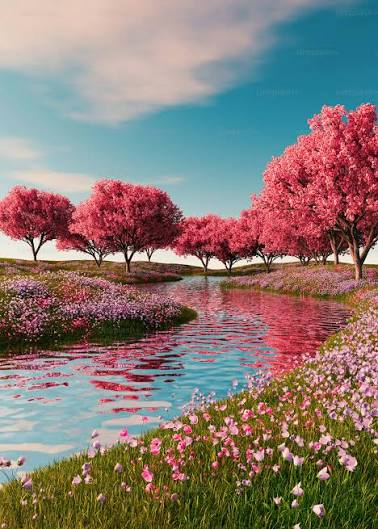

In [67]:
import base64

def analyze_image(path, model):
    with open(path, "rb") as f:
        b64 = base64.b64encode(f.read()).decode()
    prompt = """Analyze this image.

Identify:
1. Main objects
2. Environment
3. Text visible in the image
4. Possible interpretation"""
    return generate(prompt, model=model, images=[b64])

if os.path.exists(IMAGE_PATH):
    out = analyze_image(IMAGE_PATH, VISION_MODEL)
    print(out["response"], f"\n⏱ {out['wall_s']:.1f}s")
    from IPython.display import Image, display
    display(Image(IMAGE_PATH, width=400))
else:
    print(f"⚠️ Put an image named '{IMAGE_PATH}' next to this notebook, then re-run.")

### Questions
- Difference between an LLM and a multimodal model?
- What additional information does the vision model receive?
- Which applications could use local vision AI? *(document analysis, OCR, industrial inspection, education, medical-image preprocessing, surveillance analysis…)*

**✍️ Your answer:**

**Difference between an LLM and a multimodal model?** A classic LLM only processes text: it receives tokens and generates tokens. A multimodal model can also take other types of input, here images: a vision encoder turns the image into visual tokens that are given to the language model together with the text prompt. The model can then describe and analyse an image. In this lab, gemma3:4b is multimodal, whereas qwen3.5:4b was used as a text-only model.

**What additional information does the vision model receive?** In addition to the text prompt, it receives the **image itself**, encoded in base64 and sent in the `images` field of the request. It therefore has access to visual information (objects, colors, layout, environment, visible text) that the prompt does not contain. In our test, gemma3:4b analysed a landscape in 70.4 s on the CPU: it correctly identified the pink flowering trees (likely cherry blossoms), the river, the flowers along the bank, the blue sky, the spring season and the peaceful, idealised atmosphere. However, it reported a text "Unipatto" in the bottom right corner, which is not visible in the image: a **visual hallucination**, showing that the descriptions of multimodal models must be checked.

**Which applications could use local vision AI?** Document analysis and OCR (invoices, forms, handwritten notes), industrial inspection (defect detection on production lines), education (explaining diagrams or exercises), accessibility (describing images for visually impaired people), medical-image preprocessing, and analysis of surveillance footage. Running vision **locally** is especially valuable when images are sensitive (medical, personal or industrial data), since they never leave the machine.

## Part 15 — Build a Local AI Web Application
Structure:
```
local-ai-web/
├── app.py
├── templates/index.html
└── static/
```

In [68]:
!pip install -q flask requests
os.makedirs("local-ai-web/templates", exist_ok=True)
os.makedirs("local-ai-web/static", exist_ok=True)

In [71]:
%%writefile local-ai-web/app.py
from flask import Flask, render_template, request
import requests

app = Flask(__name__)

OLLAMA_URL = "http://localhost:11434/api/generate"
MODEL = "qwen3.5:4b"


@app.route("/", methods=["GET", "POST"])
def index():
    answer = ""

    if request.method == "POST":
        question = request.form["question"]
        data = {"model": MODEL, "prompt": question, "stream": False}
        response = requests.post(OLLAMA_URL, json=data)
        answer = response.json()["response"]

    return render_template("index.html", answer=answer)


if __name__ == "__main__":
    app.run(debug=True)

Overwriting local-ai-web/app.py


In [72]:
%%writefile local-ai-web/templates/index.html
<!DOCTYPE html>
<html>
<head>
    <title>Local AI Assistant</title>
</head>
<body>

<h1>Local AI Assistant</h1>

<form method="POST">
    <textarea name="question" rows="8" cols="70" placeholder="Ask your local AI..."></textarea>
    <br><br>
    <button type="submit">Ask</button>
</form>

{% if answer %}
<h2>Response</h2>
<pre>{{ answer }}</pre>
{% endif %}

</body>
</html>

Overwriting local-ai-web/templates/index.html


Run it **from a terminal** (not inside the notebook):
```bash
cd local-ai-web
python app.py
```
then open <http://127.0.0.1:5000>. 🎉 You now have a complete local AI web application.

*(📸 Take a screenshot for your report: `screenshots/06_webapp.png`.)*

## Part 16 — Performance Benchmark
We measure: response time, model size, tokens generated, tokens/second, RAM and GPU consumption.

Ollama returns precise counters: `eval_count` (generated tokens), `eval_duration` (ns), `prompt_eval_count`, `load_duration`.

In [73]:
!pip install -q psutil

In [74]:
%%writefile benchmark.py
"""Benchmark local Ollama models on the same prompt."""
import time, requests, psutil, pandas as pd

OLLAMA = "http://localhost:11434"
PROMPT = "Write a 500-word explanation of reinforcement learning."


def unload(model):
    requests.post(f"{OLLAMA}/api/generate", json={"model": model, "keep_alive": 0})
    time.sleep(2)


def loaded_info(model):
    for m in requests.get(f"{OLLAMA}/api/ps").json()["models"]:
        if m["name"].startswith(model.split(":")[0]):
            return m["size"] / 1e9, m.get("size_vram", 0) / 1e9
    return float("nan"), float("nan")


def bench(model, prompt=PROMPT, runs=1):
    rows = []
    for _ in range(runs):
        unload(model)                       # cold start, so the load time is visible
        t0 = time.perf_counter()
        r = requests.post(f"{OLLAMA}/api/generate",
                          json={"model": model, "prompt": prompt, "stream": False,
                                "think": False}, timeout=900).json()
        wall = time.perf_counter() - t0
        total_gb, vram_gb = loaded_info(model)
        rows.append({
            "Model": model,
            "Disk size (GB)": next((m["size"] / 1e9 for m in requests.get(f"{OLLAMA}/api/tags").json()["models"]
                                    if m["name"].startswith(model.split(":")[0])), float("nan")),
            "Loaded size (GB)": total_gb,
            "VRAM (GB)": vram_gb,
            "Load time (s)": r.get("load_duration", 0) / 1e9,
            "Response time (s)": wall,
            "Tokens": r.get("eval_count"),
            "Tokens/s": r["eval_count"] / (r["eval_duration"] / 1e9),
            "System RAM used (%)": psutil.virtual_memory().percent,
        })
    return pd.DataFrame(rows)


if __name__ == "__main__":
    import sys
    print(pd.concat([bench(m) for m in sys.argv[1:]]).round(2).to_string(index=False))

Writing benchmark.py


In [77]:
import benchmark; importlib.reload(benchmark)

bench_df = pd.concat([benchmark.bench(m) for m in (MODEL, MODEL2)], ignore_index=True)
bench_df["Quality /5"] = [5, 5]   # <- fill in after reading both answers
bench_df.round(2)

,Model,Disk size (GB),Loaded size (GB),VRAM (GB),Load time (s),Response time (s),Tokens,Tokens/s,System RAM used (%),Quality /5
0,qwen3.5:4b,3.32,3.15,0.0,10.21,154.49,751,5.25,89.1,5
1,gemma3:4b,3.35,2.89,0.0,22.67,95.68,799,11.10,81.8,5


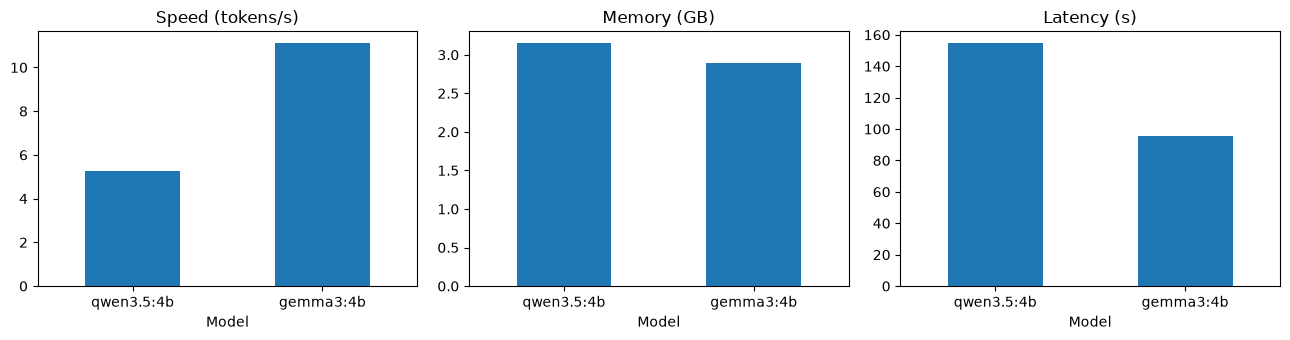

In [78]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
bench_df.plot.bar(x="Model", y="Tokens/s", ax=ax[0], legend=False, title="Speed (tokens/s)", rot=0)
bench_df.plot.bar(x="Model", y="Loaded size (GB)", ax=ax[1], legend=False, title="Memory (GB)", rot=0)
bench_df.plot.bar(x="Model", y="Response time (s)", ax=ax[2], legend=False, title="Latency (s)", rot=0)
plt.tight_layout(); plt.show()

### Discussion — the model-size trade-off
```
Model size ──► Quality
           ──► Memory
           ──► Latency
           ──► Hardware requirements
```
Local model selection should be based on **actual measurements on the target machine**, not just public benchmark rankings.

**✍️ Your discussion:**

Both models were measured on the same prompt (a 500-word explanation of reinforcement learning), from a cold start, with the thinking mode disabled, on a laptop **without a dedicated GPU** (VRAM = 0 GB: inference runs entirely on the CPU).

| Model | Disk (GB) | Loaded (GB) | Load time (s) | Response time (s) | Tokens | Tokens/s | System RAM used | Quality /5 |
|---|---|---|---|---|---|---|---|---|
| qwen3.5:4b | 3.32 | 3.15 | 10.21 | 154.49 | 751 | 5.25 | 89.1 % | 5 |
| gemma3:4b | 3.35 | 2.89 | 22.67 | 95.68 | 799 | 11.10 | 81.8 % | 5 |

**Speed:** gemma3:4b was clearly faster in this run: **11.10 tokens/s** vs 5.25, and a total response time of 95.7 s vs 154.5 s, although it generated slightly more tokens (799 vs 751). Its **load time** is longer (22.7 s vs 10.2 s), partly because gemma3 also loads its vision components; this matters for occasional requests, while tokens/s matters for long answers.

**Variability of measurements:** in a first run of the same benchmark, qwen3.5:4b reached 10.95 tokens/s (75.7 s) and gemma3:4b 12.94 tokens/s (85.5 s). The speed of qwen3.5 was halved in the second run, when the system RAM was 89 % full. On a CPU-only machine, results depend strongly on the available memory, the other running programs and the processor temperature. Measurements should therefore be repeated (the `runs` parameter) and averaged, with other applications closed.

**Memory:** both models have similar sizes on disk (about 3.3 GB, Q4_K_M quantization). Once loaded, gemma3:4b uses slightly less memory (2.89 GB vs 3.15 GB).

**Quality:** both texts were coherent and relevant (5/5).

**Conclusion:** with two models of the same size class, the differences come from the architecture, the load time, the settings (in Part 6, the thinking mode made qwen3.5 much slower) and the state of the machine, rather than from the number of parameters. On this CPU-only laptop with 16 GB of RAM, both 4-billion-parameter models are usable, but a 7B model or larger would be much slower and could saturate the memory. This illustrates the trade-off: **a larger model may give better quality, but costs more memory, more latency and more powerful hardware**. On this machine, gemma3:4b offers the best balance between speed, memory and quality.

## Part 17 — Final Mini Project: **FSTT Local AI Assistant**

**Functional requirements:** runs entirely locally · uses Ollama + a local LLM · web interface · answers questions about a supplied course · uses local documents as knowledge · maintains conversation history · structured responses for selected questions · displays the answer · records response time.

```
Browser → Flask/Python ─┬─ Conversation history ─┐
                        └─ Documents → Retriever ┴─► Ollama → Local LLM
```

We reuse `rag.py` and create the final deliverable layout:
```
LocalAI_Lab/
├── source/ (app.py, chatbot.py, rag.py, benchmark.py, templates/)
├── documents/
├── screenshots/
├── report.pdf
└── README.md
```

In [80]:
import shutil
base = "LocalAI_Lab"
for d in ("source/templates", "documents", "screenshots"):
    os.makedirs(f"{base}/{d}", exist_ok=True)

# copy shared modules and documents into the deliverable layout
shutil.copy("rag.py", f"{base}/source/rag.py")
shutil.copy("benchmark.py", f"{base}/source/benchmark.py")
for fn in os.listdir("documents"):
    shutil.copy(f"documents/{fn}", f"{base}/documents/{fn}")
print(sorted(os.listdir(base)))

['documents', 'screenshots', 'source']


In [81]:
%%writefile LocalAI_Lab/source/chatbot.py
"""Console chatbot with conversation memory (uses /api/chat)."""
import requests

OLLAMA = "http://localhost:11434"
MODEL = "qwen3.5:4b"


def main():
    messages = [{"role": "system", "content": "You are a helpful, concise assistant."}]
    print("Local AI Assistant — type 'exit' to stop.")
    while True:
        q = input("\nYou: ")
        if q.lower() == "exit":
            break
        messages.append({"role": "user", "content": q})
        r = requests.post(f"{OLLAMA}/api/chat",
                          json={"model": MODEL, "messages": messages, "stream": False})
        r.raise_for_status()
        reply = r.json()["message"]
        messages.append({"role": "assistant", "content": reply["content"]})
        print("\nAI:", reply["content"])


if __name__ == "__main__":
    main()

Writing LocalAI_Lab/source/chatbot.py


In [82]:
%%writefile LocalAI_Lab/source/app.py
"""FSTT Local AI Assistant — Flask + Ollama + local RAG + conversation history."""
import json, os, time
import requests
from flask import Flask, jsonify, render_template, request

import rag

OLLAMA = os.environ.get("OLLAMA_URL", "http://localhost:11434")
MODEL = os.environ.get("MODEL", "qwen3.5:4b")
DOC_DIR = os.path.join(os.path.dirname(__file__), "..", "documents")
MAX_TURNS = 6                      # remembered user/assistant pairs

app = Flask(__name__)
retriever = rag.Retriever(rag.load_documents(DOC_DIR))
history = []                       # [{"role": ..., "content": ...}]  (single-user demo)

SYSTEM = ("You are the FSTT Local AI Assistant. Answer questions about the course using only the "
          "provided CONTEXT. If the answer is not in the context, say: \"Information not available.\" "
          "Be concise.")

# Structured response schema used for "Analyze ..." / "Quiz ..." style questions
STRUCT_SCHEMA = {
    "type": "object",
    "properties": {
        "topic": {"type": "string"},
        "summary": {"type": "string"},
        "key_points": {"type": "array", "items": {"type": "string"}},
        "difficulty": {"type": "string", "enum": ["easy", "medium", "hard"]},
    },
    "required": ["topic", "summary", "key_points", "difficulty"],
}


def call_ollama(messages, structured=False):
    payload = {"model": MODEL, "messages": messages, "stream": False, "think": False}
    if structured:
        payload["format"] = STRUCT_SCHEMA
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()


@app.route("/")
def index():
    return render_template("index.html", model=MODEL, docs=list(retriever.docs))


@app.route("/ask", methods=["POST"])
def ask():
    body = request.get_json(force=True)
    question = (body.get("question") or "").strip()
    structured = bool(body.get("structured"))
    if not question:
        return jsonify(error="Empty question"), 400

    hits, context = retriever.context(question, k=2)
    user_msg = f"CONTEXT:\n{context or '(none)'}\n\nQUESTION: {question}"
    messages = [{"role": "system", "content": SYSTEM}] + history[-2 * MAX_TURNS:] \
               + [{"role": "user", "content": user_msg}]

    t0 = time.perf_counter()
    try:
        out = call_ollama(messages, structured)
    except requests.RequestException as e:
        return jsonify(error=f"Ollama error: {e}"), 502
    elapsed = time.perf_counter() - t0

    answer = out["message"]["content"]
    # store the plain question (not the long context) to keep history small
    history.append({"role": "user", "content": question})
    history.append({"role": "assistant", "content": answer})

    parsed = None
    if structured:
        try:
            parsed = json.loads(answer)
        except json.JSONDecodeError:
            pass

    tokens = out.get("eval_count")
    tps = tokens / (out["eval_duration"] / 1e9) if tokens and out.get("eval_duration") else None
    return jsonify(answer=answer, structured=parsed,
                   sources=[{"doc": n, "score": round(s, 2)} for n, s in hits],
                   seconds=round(elapsed, 2), tokens=tokens,
                   tokens_per_s=round(tps, 1) if tps else None)


@app.route("/reset", methods=["POST"])
def reset():
    history.clear()
    return jsonify(ok=True)


if __name__ == "__main__":
    # Bind to localhost ONLY (see report question Q15 on security)
    app.run(host="127.0.0.1", port=int(os.environ.get("PORT", 5001)), debug=False)

Writing LocalAI_Lab/source/app.py


In [83]:
%%writefile LocalAI_Lab/source/templates/index.html
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<title>FSTT Local AI Assistant</title>
<style>
  body { font-family: system-ui, sans-serif; max-width: 820px; margin: 2rem auto; padding: 0 1rem; color:#222; }
  h1 { margin-bottom: .2rem; } .sub { color:#666; font-size:.9rem; margin-bottom:1rem; }
  #chat { border:1px solid #ddd; border-radius:8px; padding:1rem; height:420px; overflow-y:auto; background:#fafafa; }
  .msg { margin:.6rem 0; padding:.6rem .8rem; border-radius:8px; white-space:pre-wrap; }
  .user { background:#e3f0ff; } .ai { background:#fff; border:1px solid #e5e5e5; }
  .meta { font-size:.75rem; color:#777; margin-top:.3rem; }
  form { display:flex; gap:.5rem; margin-top:1rem; } input[type=text] { flex:1; padding:.6rem; }
  button { padding:.6rem 1rem; cursor:pointer; } label { font-size:.85rem; }
</style>
</head>
<body>
<h1>🎓 FSTT Local AI Assistant</h1>
<div class="sub">Model: <b>{{ model }}</b> · Documents: {{ docs|join(", ") }} · Runs 100% locally</div>
<div id="chat"></div>
<form id="f">
  <input type="text" id="q" placeholder="Ask a question about the course..." autocomplete="off" autofocus>
  <button type="submit">Ask</button>
  <button type="button" id="reset">Reset</button>
</form>
<label><input type="checkbox" id="struct"> Structured response (JSON)</label>

<script>
const chat = document.getElementById("chat");
function add(cls, text, meta) {
  const d = document.createElement("div"); d.className = "msg " + cls; d.textContent = text;
  if (meta) { const m = document.createElement("div"); m.className = "meta"; m.textContent = meta; d.appendChild(m); }
  chat.appendChild(d); chat.scrollTop = chat.scrollHeight; return d;
}
document.getElementById("f").onsubmit = async (e) => {
  e.preventDefault();
  const q = document.getElementById("q"); const question = q.value.trim(); if (!question) return;
  q.value = ""; add("user", question);
  const wait = add("ai", "…thinking…");
  try {
    const r = await fetch("/ask", {method:"POST", headers:{"Content-Type":"application/json"},
      body: JSON.stringify({question, structured: document.getElementById("struct").checked})});
    const j = await r.json(); wait.remove();
    if (j.error) { add("ai", "⚠️ " + j.error); return; }
    const text = j.structured ? JSON.stringify(j.structured, null, 2) : j.answer;
    const src = j.sources.map(s => s.doc).join(", ") || "none";
    add("ai", text, `⏱ ${j.seconds}s · ${j.tokens ?? "?"} tokens · ${j.tokens_per_s ?? "?"} tok/s · sources: ${src}`);
  } catch (err) { wait.remove(); add("ai", "⚠️ " + err); }
};
document.getElementById("reset").onclick = async () => { await fetch("/reset", {method:"POST"}); chat.innerHTML = ""; };
</script>
</body>
</html>

Writing LocalAI_Lab/source/templates/index.html


In [85]:
%%writefile LocalAI_Lab/README.md
# FSTT Local AI Assistant

A fully local assistant: Flask web UI → Ollama → local LLM, with a keyword (TF-IDF) retriever over `documents/`,
conversation history, structured (JSON) answers and response-time display.

## Setup
```bash
ollama pull qwen3.5
pip install flask requests psutil pandas
```

## Run
```bash
cd source
python app.py            # http://127.0.0.1:5001
python chatbot.py        # console chatbot
python benchmark.py qwen3.5:4b gemma3:4b
```
Environment variables: `MODEL`, `OLLAMA_URL`, `PORT`.

Overwriting LocalAI_Lab/README.md


**Test the final app from the notebook:** launch it as a background process, send a few questions, then stop it.

In [88]:
import subprocess, sys, time

env = {**os.environ, "MODEL": MODEL, "PORT": "5001"}
server = subprocess.Popen([sys.executable, "app.py"], cwd="LocalAI_Lab/source", env=env,
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
time.sleep(3)

def app_ask(q, structured=False):
    r = requests.post("http://127.0.0.1:5001/ask", json={"question": q, "structured": structured}, timeout=600)
    return r.json()

try:
    for q, s in [("What is reinforcement learning?", False),
                 ("And how is it different from supervised learning?", False),   # tests history
                 ("Summarize deep learning", True),                              # structured
                 ("What is quantum computing?", False)]:                         # not in the docs
        j = app_ask(q, s)
        print(f"Q: {q}\nA: {j.get('structured') or j.get('answer') or j}\n"
              f"   sources={j.get('sources')} · {j.get('seconds')}s · {j.get('tokens_per_s')} tok/s\n")
finally:
    pass  # keep running so you can open http://127.0.0.1:5001 — stop in the next cell

Q: What is reinforcement learning?
A: Reinforcement learning learns through interaction with an environment using rewards and penalties. An agent observes a state, chooses an action, and receives a reward, with the goal of learning a policy that maximises the cumulative reward. Q-learning and policy gradients are common algorithms used in this approach.
   sources=[{'doc': 'course.txt', 'score': 1.08}, {'doc': 'reinforcement_learning.txt', 'score': 1.02}] · 4.74s · 12.8 tok/s

Q: And how is it different from supervised learning?
A: Reinforcement learning uses rewards and penalties learned through interaction with an environment, whereas supervised learning works with labelled data to learn a mapping from inputs to outputs.
   sources=[{'doc': 'course.txt', 'score': 1.08}, {'doc': 'machine_learning.txt', 'score': 1.06}] · 5.92s · 13.0 tok/s

Q: Summarize deep learning
A: {'difficulty': 'easy', 'key_points': ['Uses artificial neural networks with many layers', 'Learns representations fro

In [87]:
server.terminate(); server.wait(timeout=10)
print("Server stopped.")

Server stopped.


> 📸 Open <http://127.0.0.1:5001> in your browser while the server is running and take your screenshots: `01_installation.png`, `02_model.png`, `03_chatbot.png`, `04_python.png`, `05_rag.png`, `06_webapp.png`.

## Part 18 — Questions for the Report
Answer each question in your own words (use your measurements from Parts 6 and 16 for Q13–Q14).

**Q1.** What is Local AI?

Local AI means running an artificial intelligence model, such as a large language model, **directly on one's own computer** instead of calling a remote cloud service. Inference is performed by the local CPU or GPU, and the data never leaves the machine. In this lab, Ollama ran qwen3.5:4b and gemma3:4b on a laptop, accessible through `localhost:11434`, without depending on an Internet connection.

**Q2.** Difference between a Cloud LLM and a Local LLM?

A **cloud LLM** (ChatGPT, Claude, Gemini) runs on the provider's servers: the application sends its data over the Internet to an API, usually pays per token, and benefits from very large and capable models. A **local LLM** runs on the user's machine: no Internet connection is needed, there is no per-token cost and the data stays private, but the model must fit in the available memory, so it is usually smaller, less capable and slower, especially without a GPU (about 5 to 13 tokens/s on our CPU-only laptop).

**Q3.** What role does Ollama play?

Ollama is the **runtime and model manager** for local LLMs. It downloads models (`ollama pull`), stores them (`ollama list`), loads them into memory when needed and unloads them after inactivity (`ollama ps`), performs inference on the CPU or GPU, and applies each model's chat template. Above all, it exposes a **local REST API** on `localhost:11434` (`/api/generate`, `/api/chat`, `/api/embed`, `/api/tags`, `/api/ps`), so that any program (terminal, Python script, Flask web application) can use the same model.

**Q4.** What is model quantization?

Quantization reduces the **numerical precision of the model's weights**, for example from 16-bit floating-point numbers to about 4 bits per weight. The model becomes much smaller and faster, with a small loss of quality. Our two models use the **Q4_K_M** format: qwen3.5:4b has 4.2 billion parameters but takes only 3.32 GB on disk, whereas the same model in 16-bit precision would need about 8 GB. Quantization is what makes it possible to run such models on a laptop.

**Q5.** Why does model size affect memory consumption?

To generate text, all the model's weights must be loaded into memory (RAM or VRAM), since each generated token requires a computation over all of them. Memory therefore grows with the number of parameters multiplied by the size of each parameter (2 bytes in 16-bit precision, about 0.5 byte in 4-bit). In addition, the context (conversation history, documents) requires extra memory for the attention cache. In our benchmark, the 4-billion-parameter models used about 2.9 to 3.2 GB once loaded.

**Q6.** Why can a smaller model sometimes be preferable?

A smaller model loads faster, generates more tokens per second, uses less memory and can run on modest hardware, such as a laptop without a GPU. For simple or well-defined tasks (answering from documents, extracting JSON, writing short functions), its quality is often sufficient: in our tests, both 4B models wrote a correct prime-number function and answered the RAG questions correctly. This is why we chose the 4-billion-parameter version of qwen3.5 (`qwen3.5:4b`) rather than a larger one, given our 16 GB of RAM and the absence of a dedicated GPU.

**Q7.** Advantages of local inference?

- **Privacy**: data (documents, code, personal information) never leaves the machine;
- **Offline operation**: the model works without an Internet connection;
- **No per-token cost** and no usage limits imposed by a provider;
- **Control**: choice of model and version, and of settings (thinking mode, structured outputs, `keep_alive`), with no dependence on an external service;
- **Easy integration** into any local application through the REST API, with no network latency to a remote server.

**Q8.** Disadvantages of local inference?

- **Hardware requirements**: enough RAM and ideally a GPU; on our CPU-only laptop, answers took from 2 seconds to more than 5 minutes (with the thinking mode enabled);
- **Lower capability** than large cloud models, since only models that fit in memory can be used;
- **Variable performance**, depending on the machine's state: in our benchmark, qwen3.5 dropped from 10.95 to 5.25 tokens/s when the system RAM was 89 % full;
- **Maintenance and security**: installing, updating and securing the models and the server are the user's responsibility.

**Q9.** Explain the architecture of your Python application.

The final application (FSTT Local AI Assistant) follows this flow: **Browser → Flask (Python) → retriever + conversation history → Ollama → local LLM**. The web page (HTML/JavaScript) sends the question to the `/ask` route of the Flask server. The server uses the TF-IDF retriever (`rag.py`) to find the two most relevant documents in the `documents/` folder, builds a list of messages containing a system prompt, the recent history (up to 6 exchanges) and the question with its context, then calls Ollama's `/api/chat` endpoint, with a JSON schema when a structured answer is requested. It returns the answer, the sources, the response time, the number of tokens and the speed, which the page displays. The history is stored in memory and can be cleared with the Reset button. In our tests, the application answered from the documents, understood a follow-up question thanks to the history, returned valid JSON, and answered "Information not available." for a question outside the documents.

**Q10.** Explain the role of the REST API.

The REST API is the **interface between the applications and the model**. Ollama listens on `localhost:11434` and receives HTTP requests with a JSON body (model, prompt or messages, options such as `stream`, `format` or `think`), and returns JSON answers containing the generated text and metadata (`total_duration`, `load_duration`, `eval_count`, `eval_duration`). Thanks to this standard interface, the same model can be used from the terminal, a Python script, a Flask web application or any other language, without depending on how the model is implemented internally. It follows the same principle as cloud APIs, which makes it easy to switch between a local and a cloud model.

**Q11.** What is RAG?

RAG (**Retrieval-Augmented Generation**) combines a **retrieval** step and a **generation** step: before asking the LLM, the system searches a knowledge base for the documents relevant to the question, inserts them into the prompt as context, and asks the model to answer only from this context. The model can thus answer about information it was never trained on, and is less likely to hallucinate. In our Mini-RAG, the TF-IDF retriever found `deep_learning.txt` for a question about hardware (answer: "GPUs"), and returned no document for "Who won the 2018 World Cup?", so the model answered "Information not available." We also observed a limit of keyword retrieval: for some questions, a shorter and less detailed document was selected. Retrieving two documents in the final application gave richer answers, and semantic embeddings would improve retrieval further.

**Q12.** Difference between an LLM and a multimodal LLM?

A classic LLM only processes text: it receives tokens and generates tokens. A multimodal LLM can also take other types of input, such as images: a vision encoder turns the image into visual tokens that are given to the language model together with the text prompt. In Part 14, gemma3:4b analysed a landscape image in 70 seconds, correctly identifying the trees in bloom, the river and the spring atmosphere, but it also reported a text that was not visible in the image, showing that multimodal answers must be checked.

**Q13.** Compare two local models experimentally.

| Model | Disk (GB) | Loaded (GB) | Load time (s) | Response time (s) | Tokens | Tokens/s | Quality /5 |
|---|---|---|---|---|---|---|---|
| qwen3.5:4b | 3.32 | 3.15 | 10.21 | 154.49 | 751 | 5.25 | 5 |
| gemma3:4b | 3.35 | 2.89 | 22.67 | 95.68 | 799 | 11.10 | 5 |

Both models have a similar size (about 4 billion parameters, Q4_K_M quantization) and run on the CPU only. In the benchmark (500-word text, thinking disabled), gemma3:4b was faster (11.10 vs 5.25 tokens/s) and used slightly less memory once loaded, but needed a longer load time (22.7 s vs 10.2 s). In a first run of the same benchmark, qwen3.5 reached 10.95 tokens/s, which shows that measurements on a CPU depend on the machine's state (available RAM, other programs, temperature). In Part 6, both models wrote a correct prime-number function (5/5, verified on all integers from -5 to 2000), and gemma3 answered faster (104 s vs 137 s, with qwen3.5's thinking mode enabled). The quality of the answers was equivalent in all our tests.

**Q14.** Which model would you deploy on a computer with limited RAM? Explain.

On a computer with limited RAM, I would deploy **gemma3:4b** among the two models tested: it uses the least memory once loaded (2.89 GB), it generated the most tokens per second in our benchmark (11.10 tokens/s), and its quality was equivalent. Its only drawback is a longer load time, which can be avoided by keeping the model in memory (`keep_alive`). With even less RAM (8 GB or less), a smaller model such as `gemma3:1b` or `qwen3:1.7b` (about 1 to 1.5 GB) would be preferable, accepting a lower quality. In any case, the choice must be based on measurements on the target machine, with other applications closed to keep enough free memory.

**Q15.** What security risks exist when exposing a local LLM server to a network?

By default, Ollama listens only on `127.0.0.1`, so only the local machine can use it. If it is exposed to the network (for example with `OLLAMA_HOST=0.0.0.0`), several risks appear, because **Ollama has no authentication by default**:
- **Unauthorized use of the computing resources**: anyone on the network can send requests, overload the machine or use it for their own purposes;
- **Model management by third parties**: the API also allows downloading or deleting models;
- **Data exposure**: prompts, documents sent as context and answers travel unencrypted over HTTP;
- **Prompt injection through documents**: a malicious document added to the knowledge base can contain instructions that manipulate the model's answers;
- **Denial of service**: long or numerous requests can saturate the CPU and memory.

To reduce these risks: keep the server bound to localhost (as in our Flask application, which uses `host="127.0.0.1"`), block port 11434 with a firewall, and if remote access is needed, place a **reverse proxy** (such as Nginx) in front of it with **authentication and TLS encryption**, limit the request rate, and check the documents added to the knowledge base.

## Part 19 — Deliverables
Final check of the submission folder:
```
LocalAI_Lab/
├── report.pdf
├── source/        app.py · chatbot.py · rag.py · benchmark.py
├── documents/     ai.txt · ml.txt · rl.txt  (+ the other course files)
├── screenshots/   01_installation.png … 06_webapp.png
└── README.md
```

In [92]:
required = [
    "LocalAI_Lab/report.pdf",
    "LocalAI_Lab/README.md",
    "LocalAI_Lab/source/app.py", "LocalAI_Lab/source/chatbot.py",
    "LocalAI_Lab/source/rag.py", "LocalAI_Lab/source/benchmark.py",
    "LocalAI_Lab/screenshots/01_installation.png", "LocalAI_Lab/screenshots/02_model.png",
    "LocalAI_Lab/screenshots/03_chatbot.png", "LocalAI_Lab/screenshots/04_python.png",
    "LocalAI_Lab/screenshots/05_rag.png", "LocalAI_Lab/screenshots/06_webapp.png",
]
for p in required:
    print("✅" if os.path.exists(p) else "⬜ missing", p)
print("\nDocuments:", sorted(os.listdir("LocalAI_Lab/documents")))

✅ LocalAI_Lab/report.pdf
✅ LocalAI_Lab/README.md
✅ LocalAI_Lab/source/app.py
✅ LocalAI_Lab/source/chatbot.py
✅ LocalAI_Lab/source/rag.py
✅ LocalAI_Lab/source/benchmark.py
✅ LocalAI_Lab/screenshots/01_installation.png
✅ LocalAI_Lab/screenshots/02_model.png
✅ LocalAI_Lab/screenshots/03_chatbot.png
✅ LocalAI_Lab/screenshots/04_python.png
✅ LocalAI_Lab/screenshots/05_rag.png
✅ LocalAI_Lab/screenshots/06_webapp.png

Documents: ['ai.txt', 'course.txt', 'deep_learning.txt', 'machine_learning.txt', 'reinforcement_learning.txt']
